# 07 - Deep Learning Models: LSTM and PatchTST

In this notebook I build the two deep learning models with the `neuralforecast` library:
- **LSTM:** looks at the last 168 hours of load, plus the calendar features and temperature for the next 24 hours
- **PatchTST:** a transformer that looks at the last 168 hours of load only (this model does not accept extra features)

Both forecast all 24 hours at once (not recursively like XGBoost).

### 1. Import libraries and load the data

In [1]:
import os
import logging
import warnings

# if the GPU does not support an operation, run that operation on the CPU
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import pandas as pd
import matplotlib.pyplot as plt
from neuralforecast import NeuralForecast
from neuralforecast.models import LSTM, PatchTST

# hide the long training messages
warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"
os.makedirs(forecast_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)

In [2]:
data = pd.read_csv("../datasets/processed/gb_features_2015_2019.csv")

# the Nixtla libraries need three columns: unique_id, ds (time) and y (value to forecast)
df = pd.DataFrame()
df["unique_id"] = ["GB"] * len(data)
df["ds"] = pd.to_datetime(data["time"]).dt.tz_localize(None)   # time in UTC, without the time zone label
df["y"] = data["load"]

extra_features = ["hour", "day_of_week", "month", "is_weekend", "is_holiday", "temperature"]
for col in extra_features:
    df[col] = data[col]

df.head()

,unique_id,ds,y,hour,day_of_week,month,is_weekend,is_holiday,temperature
0,GB,2015-01-08 00:00:00,32593.0,0,3,1,0,0,8.582
1,GB,2015-01-08 01:00:00,31607.0,1,3,1,0,0,8.491
2,GB,2015-01-08 02:00:00,30136.0,2,3,1,0,0,8.333
3,GB,2015-01-08 03:00:00,29286.0,3,3,1,0,0,8.099
4,GB,2015-01-08 04:00:00,27746.0,4,3,1,0,0,7.862


### How the forecasts are made

The same setup is used for every model:
- The model is trained on data **before 2019**.
- Then, for **every day of 2019** (365 days), it forecasts the **next 24 hours** from midnight (UTC).
- Each day it uses the real data up to that midnight, but the model itself is not trained again.

This gives 365 × 24 = 8,760 forecasts for each model. The library function `cross_validation` does this for me.

### 2. Training settings

- **Input:** the last 168 hours (1 week)
- **Output:** the next 24 hours
- **Scaling:** the load is standardised inside the model
- **Tuning with the validation year:** the model trains on 2015-2017 and checks its error on 2018 every 50 steps.
  When the 2018 error stops improving for 5 checks, training stops (early stopping). The test year 2019 is not used for this.
- `random_seed=1` so the results can be repeated

In [3]:
settings = dict(
    h=24,
    input_size=168,
    max_steps=2000,
    val_check_steps=50,
    early_stop_patience_steps=5,
    scaler_type="standard",
    random_seed=1,
    enable_progress_bar=False,
    enable_model_summary=False,
    logger=False,
)

### 3. LSTM

In [4]:
lstm = LSTM(futr_exog_list=extra_features, **settings)
lstm_model = NeuralForecast(models=[lstm], freq="h")
lstm_cv = lstm_model.cross_validation(df=df, n_windows=365, step_size=24, refit=False, val_size=8760)

lstm_mae = (lstm_cv["y"] - lstm_cv["LSTM"]).abs().mean()
print("LSTM MAE on 2019:", round(lstm_mae), "MW")

Seed set to 1


LSTM MAE on 2019: 1139 MW


### 4. PatchTST

In [5]:
patchtst = PatchTST(**settings)
patchtst_model = NeuralForecast(models=[patchtst], freq="h")
patchtst_cv = patchtst_model.cross_validation(df=df, n_windows=365, step_size=24, refit=False, val_size=8760)

patchtst_mae = (patchtst_cv["y"] - patchtst_cv["PatchTST"]).abs().mean()
print("PatchTST MAE on 2019:", round(patchtst_mae), "MW")

Seed set to 1


PatchTST MAE on 2019: 1247 MW


### 5. Plot one week

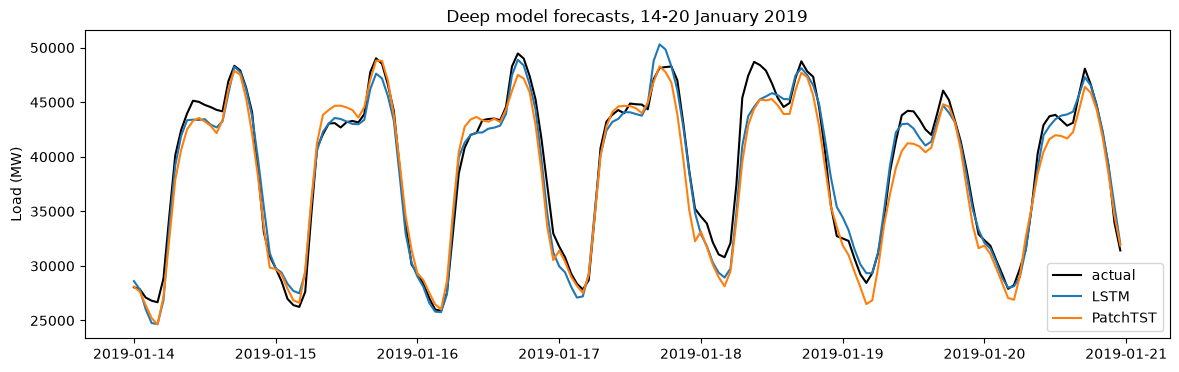

In [6]:
week = (lstm_cv["ds"] >= "2019-01-14") & (lstm_cv["ds"] < "2019-01-21")

plt.figure(figsize=(14, 4))
plt.plot(lstm_cv[week]["ds"], lstm_cv[week]["y"], label="actual", color="black")
plt.plot(lstm_cv[week]["ds"], lstm_cv[week]["LSTM"], label="LSTM")
plt.plot(patchtst_cv[week]["ds"], patchtst_cv[week]["PatchTST"], label="PatchTST")
plt.title("Deep model forecasts, 14-20 January 2019")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/07_deep_week.png")
plt.show()

### 6. Save

In [7]:
def save_forecasts(cv, model_column, file_name):
    out = pd.DataFrame()
    out["time"] = cv["ds"]
    out["cutoff"] = cv["cutoff"]
    out["actual"] = cv["y"]
    out["forecast"] = cv[model_column]
    out.to_csv(forecast_folder + "/" + file_name, index=False)

save_forecasts(lstm_cv, "LSTM", "lstm.csv")
save_forecasts(patchtst_cv, "PatchTST", "patchtst.csv")

print("Saved")

Saved


### Summary

- LSTM: 168 hours of load + calendar + temperature
- PatchTST: 168 hours of load only
- Early stopping on 2018, so 2019 is only used for the final test
- Forecasts saved in `results/forecasts/`

**Note:** the deep models train on 2015-2017 because 2018 is used for early stopping. The other models also learn from 2018.

**Next:** notebook 08 - compare all models.